# Line Chart

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

The standard way to show a continuous series over time. Points joined by a line put the reader's attention on the trend, its direction, speed and turning points, more than on any single value.

## When to use

- Show a trend in a continuous measure over regular time intervals
- Compare a few series (up to ~4) on the same scale
- Make peaks, troughs and turning points visible

## Avoid when

- The data are discrete categories with no order (use a bar chart)
- There are only 2–3 time points (use a slope chart or bars)
- More than ~5 series would overlap into spaghetti (use small multiples or highlighting)

## Alternatives

- Highlighted line chart
- Small-multiple lines
- Area chart

## Design tips

- Use a 2px line; markers only for sparse data
- Label lines directly at their end instead of using a distant legend
- The y-axis may start above zero for lines (unlike bars), but say so if the change looks exaggerated

## Example

Monthly active users of three apps over three years, synthetic data.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"

import numpy as np
import pandas as pd
import altair as alt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]


@alt.theme.register("vizlib", enable=True)
def vizlib_theme():
    return alt.theme.ThemeConfig({
        "config": {
            "background": "#fcfcfb",
            "view": {"stroke": None},
            "range": {"category": PALETTE},
            "font": "Helvetica, Arial, sans-serif",
            "title": {"anchor": "start", "fontSize": 14, "color": "#0b0b0b"},
            "axis": {"gridColor": "#e6e5e1", "domainColor": "#c9c8c3", "tickColor": "#c9c8c3",
                     "labelColor": "#52514e", "titleColor": "#52514e", "titleFontWeight": "normal"},
            "legend": {"labelColor": "#52514e", "titleColor": "#52514e"},
        }
    })
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
rng = np.random.default_rng(1)
dates = pd.date_range("2022-01", periods=36, freq="MS")
t = np.arange(36)
df = pd.DataFrame({
    "date": dates,
    "App A": 120 + 4.0 * t + rng.normal(0, 6, 36),
    "App B": 180 + 1.2 * t + 15 * np.sin(t / 3) + rng.normal(0, 6, 36),
    "App C": 60 + 0.15 * t ** 2 + rng.normal(0, 5, 36),
}).set_index("date")
labels = dict(y="Monthly active users (k)", title="Monthly active users by app")
df.head()

,App A,App B,App C
date,,,
2022-01-01,122.073505,176.915962,55.945927
2022-02-01,128.929709,176.219469,63.911219
2022-03-01,129.982622,192.680336,61.867233
2022-04-01,124.181057,196.876149,65.829415
2022-05-01,141.432135,192.014956,60.673921


### Plot

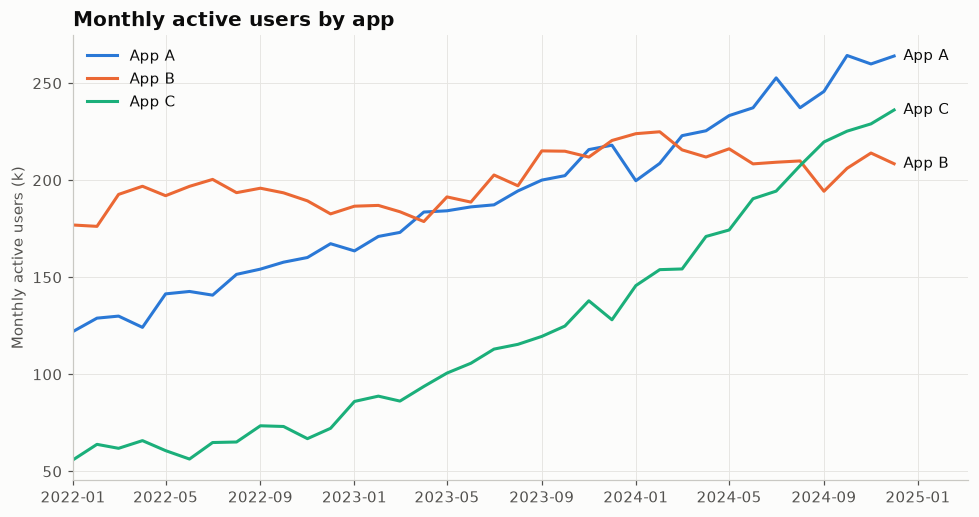

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for i, col in enumerate(df.columns):
    ax.plot(df.index, df[col], color=PALETTE[i], label=col)
    ax.text(df.index[-1] + pd.Timedelta(days=12), df[col].iloc[-1], col,
            color="#0b0b0b", va="center", fontsize=10)
ax.set_ylabel(labels["y"])
ax.set_title(labels["title"])
ax.set_xlim(df.index[0], df.index[-1] + (df.index[-1] - df.index[0]) * 0.09)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

## How to read it

Each line is one app. Its slope is the growth rate. App C starts lowest but accelerates (its curve bends upward) and overtakes App B in the final year.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
long = df.reset_index().melt(id_vars=df.index.name or "index", var_name="series", value_name="value")
fig = px.line(long, x=long.columns[0], y="value", color="series", color_discrete_sequence=PALETTE,
              labels={"value": labels["y"], long.columns[0]: ""}, title=labels["title"])
fig.update_layout(hovermode="x unified")
fig.show()

### altair

In [5]:
import altair as alt
long = df.reset_index().melt(id_vars=df.index.name or "index", var_name="series", value_name="value")
xcol = long.columns[0]
hover = alt.selection_point(fields=[xcol], nearest=True, on="pointerover", empty=False)
lines = alt.Chart(long).mark_line(strokeWidth=2).encode(
    x=alt.X(f"{xcol}:T", title=None), y=alt.Y("value:Q", title=labels["y"]),
    color=alt.Color("series:N", title=None))
rule = alt.Chart(long).mark_rule(color="#b8b7b1").encode(
    x=f"{xcol}:T", opacity=alt.condition(hover, alt.value(1), alt.value(0)),
    tooltip=[alt.Tooltip(f"{xcol}:T"), "series:N", alt.Tooltip("value:Q", format=".2f")]).add_params(hover)
chart = (lines + rule).properties(title=labels["title"], width=560, height=300)
chart

alt.LayerChart(...)

## Try it with real data

**Source:** plotly.express.data.stocks() — weekly closing prices of large tech stocks 2018–2019 (normalised), bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [6]:
import plotly.express as px
df = (px.data.stocks().assign(date=lambda d: pd.to_datetime(d["date"]))
        .set_index("date")[["GOOG", "AAPL", "AMZN"]])
labels = dict(y="Share price (1 Jan 2018 = 1)", title="Weekly share prices, 2018–2019")
df.head()

,GOOG,AAPL,AMZN
date,,,
2018-01-01,1.000000,1.000000,1.000000
2018-01-08,1.018172,1.011943,1.061881
2018-01-15,1.032008,1.019771,1.053240
2018-01-22,1.066783,0.980057,1.140676
2018-01-29,1.008773,0.917143,1.163374


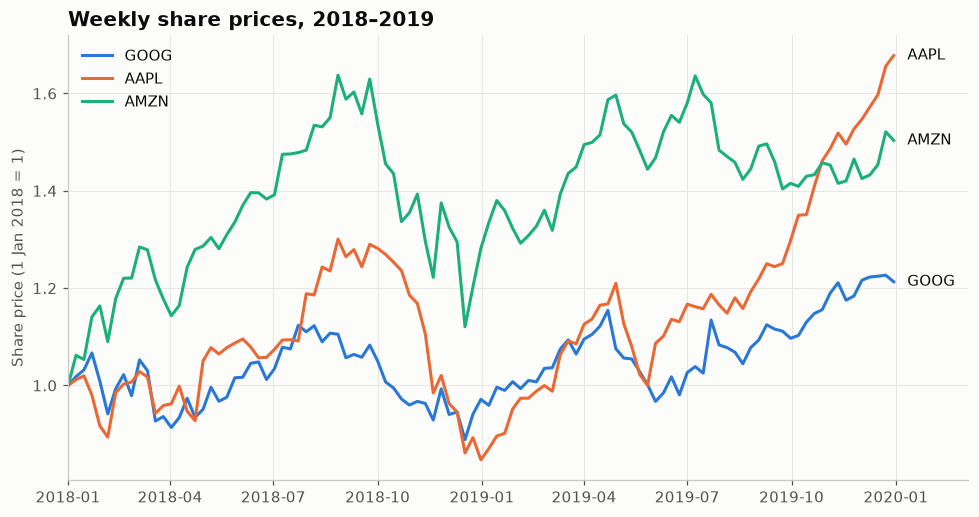

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for i, col in enumerate(df.columns):
    ax.plot(df.index, df[col], color=PALETTE[i], label=col)
    ax.text(df.index[-1] + pd.Timedelta(days=12), df[col].iloc[-1], col,
            color="#0b0b0b", va="center", fontsize=10)
ax.set_ylabel(labels["y"])
ax.set_title(labels["title"])
ax.set_xlim(df.index[0], df.index[-1] + (df.index[-1] - df.index[0]) * 0.09)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

---
Standalone script: [`line_chart.py`](line_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)